# Lesson 3a: Soft materials and scaffolds

**Goal:** understand the mechanics behind tissue engineering, and why matching a scaffold's
stiffness to the target tissue matters, for both living tissue and soft robots.

### Background
Tissue engineering combines three ingredients, often called the **tissue engineering triad**:
1. **Cells** (e.g. muscle precursor cells, stem cells),
2. a **scaffold** that gives them a 3D structure (hydrogels such as collagen, fibrin, alginate or gelatin methacrylate (GelMA), or synthetic polymers),
3. **signals**: growth factors, mechanical stretch, electrical or light stimulation.

**Biohybrid robotics** uses engineered living tissue, usually muscle, as the actuator of a soft robot.
Landmark examples:
- **Medusoid** (Harvard/Caltech, 2012): a jellyfish-like swimmer made of rat heart muscle cells on a silicone film.
- **Tissue-engineered stingray** (Harvard, 2016): heart muscle cells made light-responsive (optogenetics), steering towards pulses of light.
- **Walking "biobots"** (University of Illinois/MIT, 2016): rings of skeletal muscle on a 3D-printed hydrogel skeleton, triggered by electrical or light pulses.
- **Living skin on a robotic finger** (University of Tokyo, 2022): cultured skin tissue wrapped around a moving finger, able to heal small cuts.

### Why stiffness matters
Cells sense how stiff their surroundings are. A classic 2006 study (Engler et al., *Cell*) showed that
mesenchymal stem cells drift towards neuron-like, muscle-like or bone-like fates on substrates
matching brain, muscle or bone stiffness. So a scaffold isn't just a support: its mechanics are a signal.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

plt.rcParams["figure.figsize"] = (8, 4.5)
rng = np.random.default_rng(3)

## 1. Stiffness across tissues and materials

Stiffness is measured by the **Young's modulus** *E*: stress (force per area, in Pascal) divided by
strain (relative stretch). Values below are approximate orders of magnitude from the literature.

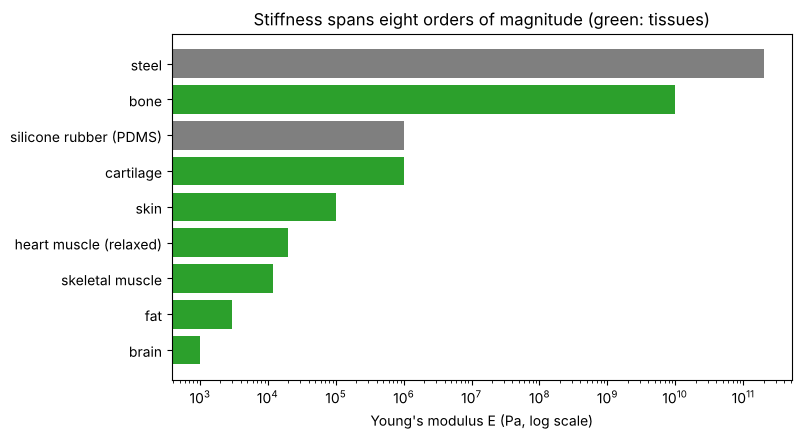

In [2]:
materials = {
    "brain": 1e3, "fat": 3e3, "skeletal muscle": 12e3, "heart muscle (relaxed)": 20e3,
    "skin": 1e5, "cartilage": 1e6, "silicone rubber (PDMS)": 1e6, "bone": 1e10, "steel": 2e11,
}
names, E = zip(*sorted(materials.items(), key=lambda kv: kv[1]))
colors = ["tab:green" if n in ("brain", "fat", "skeletal muscle", "heart muscle (relaxed)", "skin", "cartilage", "bone")
          else "tab:grey" for n in names]
plt.barh(names, E, color=colors)
plt.xscale("log"); plt.xlabel("Young's modulus E (Pa, log scale)")
plt.title("Stiffness spans eight orders of magnitude (green: tissues)")
plt.show()

Soft tissues are thousands of times softer than the silicone most soft robots are made of.
A muscle actuator on a too-stiff skeleton can't bend it; on a too-soft one, it just crumples it.

## 2. Measuring stiffness: a tensile test

Stretch a sample, record the stress, and fit the slope of the initial linear region. Below:
simulated data from a soft hydrogel. Soft materials also stiffen at large strain, so we only fit the
first 10%.

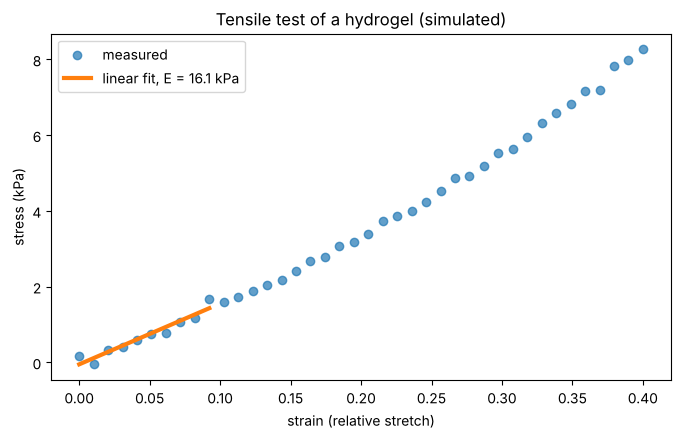

In [3]:
strain = np.linspace(0, 0.4, 40)
E_true = 15e3                                            # Pa
stress_true = E_true * strain * (1 + 2.5 * strain**2)    # strain-stiffening at large stretch
stress = stress_true + rng.normal(0, 80, strain.size)

linear = strain <= 0.10
E_fit, intercept = np.polyfit(strain[linear], stress[linear], 1)

plt.plot(strain, stress / 1e3, "o", alpha=0.7, label="measured")
plt.plot(strain[linear], (E_fit * strain[linear] + intercept) / 1e3, lw=3, label=f"linear fit, E = {E_fit/1e3:.1f} kPa")
plt.xlabel("strain (relative stretch)"); plt.ylabel("stress (kPa)"); plt.legend()
plt.title("Tensile test of a hydrogel (simulated)")
plt.show()

## 3. Tuning a hydrogel

Hydrogel stiffness depends strongly on polymer concentration, often roughly as a power law,
$E = a\,c^b$. We fit that relationship from (simulated) measurements, then **invert** it to design a
gel with the stiffness we want. This is the everyday design loop of a tissue engineering lab.

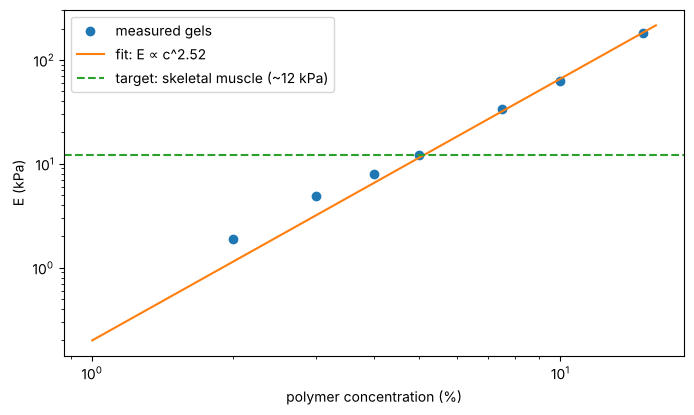

To match skeletal muscle, use about 5.1% polymer.


In [4]:
conc = np.array([2, 3, 4, 5, 7.5, 10, 15])        # % weight per volume
E_meas = 400 * conc**2.2 * rng.lognormal(0, 0.12, conc.size)   # Pa (illustrative)

def power_law(c, a, b):
    return a * c**b

(a, b), _ = curve_fit(power_law, conc, E_meas, p0=[100, 2])
cc = np.linspace(1, 16, 200)
plt.loglog(conc, E_meas / 1e3, "o", label="measured gels")
plt.loglog(cc, power_law(cc, a, b) / 1e3, label=f"fit: E ∝ c^{b:.2f}")
plt.axhline(12, color="tab:green", ls="--", label="target: skeletal muscle (~12 kPa)")
plt.xlabel("polymer concentration (%)"); plt.ylabel("E (kPa)"); plt.legend()
plt.show()

target = 12e3
c_needed = (target / a) ** (1 / b)
print(f"To match skeletal muscle, use about {c_needed:.1f}% polymer.")

## Recap

- Tissue engineering = cells + scaffold + signals, and the scaffold's mechanics are themselves a signal.
- Tissues are very soft (kPa), engineering materials very stiff (MPa to GPa); biohybrid robots have to bridge that gap.
- Fitting simple models to measurements (a modulus, a power law) and inverting them is how materials get designed.

**Your turn:**
1. Change `target` to the stiffness of heart muscle. Which concentration do you need?
2. In section 2, fit the first 30% of strain instead of 10%. How wrong does *E* get, and why?
3. A biohybrid walker needs a skeleton stiff enough to hold its shape but soft enough for the muscle to bend it. If the muscle generates about 1 kPa of stress, what range of skeleton stiffness would you aim for? (There's no single right answer; reason about the strain you want.)